# 과제 4: 제주어 한국어 생성 모델 보고서

**202435119 한여원**

KoGPT2를 AI Hub 제주어 발화 데이터로 전체 미세조정(Full fine-tuning) 및 LoRA 학습하고, 원본과 동일한 테스트 데이터의 Perplexity, 학습시간, 생성 결과를 비교한다.

*이 파일은 보고서용 템플릿이다.* [**github 주소**](https://github.com/Sperodd/kogpt-jeju)

`python experiment.py`를 실행하면 실제 학습·평가 후 `outputs/assignment4/`에 **실행 결과가 포함된 동명 노트북**이 생성된다. 제출에는 출력이 포함된 버전을 사용한다. 기존 웹 실험 모델은 새 테스트와 학습 문장이 겹칠 수 있어 본 비교에는 재사용하지 않는다.

## 1. 데이터셋 선정

출처는 [AI Hub 한국어 방언 발화(제주도)](https://www.aihub.or.kr/aihubdata/data/view.do?dataSetSn=121)의 ‘(비식별화완료)제주도_학습용데이터_1’이다. 이 과제에서는 음성이 아닌 JSON의 발화 전사문을 사용한다. JSON에는 대화 ID, 발화 ID, form, standard_form, eojeolList 등이 포함되어 있다.

일반 한국어 모델이 제주어 어휘와 어미, 구어체 발화 방식에 적응하는 과정을 관찰하기 위해 선정했다. 표준형과 비교하여 방언 특성이 있는 문장을 선택할 수 있고 대화 ID로 분할할 수 있어, 특정 영역의 언어 생성이라는 과제 목적에 적합하다. 이는 방언을 표준어로 번역하는 과제가 아니라 제주어 문장 이어쓰기 과제이다.

현재 로컬 원천 폴더에서 JSON 5,042개를 확인했다. 실행 비용을 제한하면서 다양한 대화를 포함하기 위해, 기본 실험은 고정 시드 42로 섞은 JSON 중 **300개 대화**를 선택한다. 전체 데이터 사용이라고 표기하지 않는다. 실제 선택 수와 전처리 결과는 아래 실행 출력에 기록된다. 원본 데이터 이용 조건을 따르며 공개 Git에는 원천 데이터와 학습 가중치를 포함하지 않는다.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

RUN_DIR = Path(os.environ.get("JEJU_RUN_DIR", "outputs/assignment4")).resolve()
report_path = RUN_DIR / "experiment_report.json"
if not report_path.is_file():
    raise FileNotFoundError("먼저 프로젝트 폴더에서 python experiment.py를 실행하세요.")
report = json.loads(report_path.read_text(encoding="utf-8"))
assert report["status"] == "complete", "Full/LoRA 학습과 테스트가 아직 끝나지 않았습니다."
display(pd.DataFrame([report["environment"]]))
data = report["data"]
print("원천 JSON:", data["available_json_files"], " / 선택 JSON:", data["selected_json_files"])
display(pd.DataFrame([data["raw_and_removed_counts"]]))

,python,torch,transformers,device,gpu
0,3.12.3,2.15.0+cu132,4.57.1,cuda,NVIDIA RTX PRO 4500 Blackwell Server Edition


원천 JSON: 5042  / 선택 JSON: 300


,raw_utterances,same_as_standard,fewer_than_two_words,anonymization_marker,exact_duplicate
0,165842,90808,3117,6187,659


## 2. 데이터 가공과 분할

1. form과 standard_form이 같은 발화를 제외하여 방언 표기가 있는 발화에 집중한다. 이 조건은 완벽한 방언 판별기가 아니며 선택 편향이 생길 수 있다.
2. 비식별화 표시 `{`가 있는 어절을 포함하는 발화는 전체 제외한다. 남은 고유명사까지 자동 검증한 것은 아니다.
3. eojeolList에서 슬래시 앞 표현을 취하고 한글·한글 자모만 남긴 뒤 공백으로 연결한다. 숫자·문장부호와 억양 정보는 손실되는 단순 정제 방식이다.
4. 정제 후 2어절 미만인 발화를 제외한다. 이는 짧은 맞장구의 비중을 줄이지만 자연스러운 단어 단위 발화도 제외할 수 있다.
5. JSON 대화 ID를 기준으로 약 80/10/10으로 나누고 train→validation→test 순서로 완전 동일한 문장을 제거한다. 파일 비율과 최종 문장 비율은 다르다. 파일별 로컬 speaker_id는 전역 화자 ID로 사용할 수 없어, 대화 분리는 보장하지만 화자 독립은 주장하지 않는다.
6. 동일한 KoGPT2 토크나이저로 BOS + 최대 126개 내용 토큰 + EOS를 만든다. PAD는 손실에서 제외하고 EOS는 포함한다. 긴 문장은 자르므로 평가 범위는 보존된 토큰에 한정된다.

학습은 train만 사용한다. validation 손실로 최적 에포크를 선택하고, 두 방식의 학습과 선택이 모두 끝난 후 test를 최종 평가한다. split 파일의 SHA-256과 그룹·문장 중복을 실행 전에 검사한다.

In [2]:
split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "documents": [data["split_documents"][s] for s in ["train", "validation", "test"]],
    "sentences": [data["split_sentences"][s] for s in ["train", "validation", "test"]],
    "truncated_sentences": [report["truncated_sentences"][s] for s in ["train", "validation", "test"]],
})
display(split_table)
print(data["split_note"])
print("split SHA-256:", data["split_sha256"])

,split,documents,sentences,truncated_sentences
0,train,240,53561,0
1,validation,30,6478,0
2,test,30,5032,0


대화 JSON 단위 80/10/10. 문장 비율은 달라질 수 있음. 파일 간 동일 화자는 확인되지 않아 화자 독립을 보장하지 않음.
split SHA-256: {'train': '635252b71c0fa1ed4a8267f87ab448f8713ee28b86f451e68188842cb23ab98e', 'validation': 'c07c9dee4aba9999f5d50125c1a0dfeb249fcd8dab6dad1c8b68eac870e803a8', 'test': 'cf48bfede1137432422642d04cb9d5f46aea2c9f809699724f6f961bc1ff6818'}


## 3. 사전학습 모델과 두 가지 미세조정

기반 모델은 [skt/kogpt2-base-v2](https://huggingface.co/skt/kogpt2-base-v2)이다. 한국어 생성 사전학습 모델이며 수업 예제와 같은 GPT 계열 구조를 사용하여 학습 목표를 이해하기 쉽다. 대규모 모델보다 단일 GPU에서 전체 미세조정과 파라미터 효율적 학습을 모두 비교하기에 적합하다. 지시문 응답 모델이 아니므로 질문에 정확히 답하는 챗봇 능력을 기대하지 않는다.

- **Full fine-tuning:** 기반 모델의 모든 파라미터를 업데이트하여 도메인 적응 능력을 비교한다.
- **LoRA:** 원본 파라미터를 고정하고 attention의 Q/K/V 결합 투영층 c_attn에 작은 저랭크 어댑터만 학습한다. GPT2의 Conv1D 가중치 배치에 맞춰 fan_in_fan_out=True를 사용한다. 원본 모델부터 별도로 시작하며 Full 결과에 이어서 학습하지 않는다.

| 설정 | 기본값 및 선정 이유 |
|---|---|
| 에포크 | 두 방식 모두 3회: 제한된 시간의 초기 비교이며 검증 손실로 최적 에포크 선택 |
| 배치 | 두 방식 모두 32: 사용 GPU에서 처리량 확보를 위한 시작값; OOM이면 두 방식 모두 같은 작은 배치로 재실험 |
| 최대 길이 | 128: 짧은 구어 발화 중심의 데이터에 맞추고 계산량 제한; 잘린 문장 수 별도 기록 |
| Full 학습률 | 5e-5: 사전학습 가중치의 급격한 변화를 줄이기 위한 작은 초기값 |
| LoRA 학습률 | 2e-4: 새 어댑터만 학습하므로 Full보다 큰 초기값을 사용; 최적값을 탐색했다는 의미는 아님 |
| LoRA r / alpha / dropout | 8 / 16 / 0.05: 작은 어댑터 용량과 과적합 완화를 고려한 초기 설정 |
| 옵티마이저 | AdamW, weight_decay=0.01, gradient clipping=1.0: 안정적인 업데이트를 위한 설정 |
| 정밀도 | FP32: 혼합 정밀도 설정을 배제해 실습 구조 단순화 |
| 시드 | 42: 표본, 분할, 배치 순서와 생성 설정의 재현성 확보 |

학습률이 다르므로 ‘방식 하나만 바꾼 통제 실험’이 아니라 **명시한 두 학습 구성의 비교**이다. 다중 시드·학습률 탐색을 수행하지 않았으며 최적의 방식임을 주장하지 않는다. 실제 실행 설정은 아래와 같다.

In [3]:
display(pd.DataFrame([report["config"]]))
display(pd.DataFrame([
    {"method": name, "trainable_parameters": item["trainable_parameters"],
     "total_parameters": item["total_parameters"], "learning_rate": item.get("learning_rate"),
     "best_epoch": item.get("best_epoch", 0)}
    for name, item in report["models"].items()
]))
print("LoRA:", report["models"]["lora"]["lora_config"])

,data,output,base_model,epochs,batch_size,max_length,full_lr,lora_lr,seed
0,/workspace/kogpt-jeju/prepared,/workspace/kogpt-jeju/outputs/assignment4,skt/kogpt2-base-v2,3,32,128,0.00005,0.0002,42


,method,trainable_parameters,total_parameters,learning_rate,best_epoch
0,base,0,125164032,NaN,0
1,full,125164032,125164032,0.00005,2
2,lora,294912,125458944,0.00020,3


LoRA: {'r': 8, 'alpha': 16, 'dropout': 0.05, 'target_modules': ['c_attn']}


## 4. 성능 비교: Perplexity와 학습시간

**PPL = exp(전체 평가 토큰의 평균 음의 로그우도)**이다. 각 배치의 평균 손실에 유효한 shifted target 토큰 수를 곱해 합한 뒤 전체 유효 토큰 수로 나눈다. 패딩과 BOS 자체는 예측 대상에서 빠지고, 첫 내용 토큰과 EOS는 포함된다. 배치 PPL의 단순 평균을 사용하지 않는다.

세 모델은 동일한 split·토크나이저·길이·BOS/EOS 처리로 평가한다. PPL이 낮으면 보존된 제주어 토큰을 더 잘 예측했다는 의미이지 ‘제주어 정확도 몇 %’가 아니다. 검증은 에포크 선택에 사용했고 최종 비교는 테스트 PPL로 보고한다.

train_seconds는 순수 학습 반복(데이터 배치 로딩, forward/backward, optimizer) 시간이다. fit_seconds는 에포크 검증과 체크포인트 저장을 포함한다. 모델 다운로드·토큰화·최종 테스트는 제외한다. 원본 모델의 추가 학습시간은 0이며 사전학습 비용이 0이라는 뜻은 아니다.

In [4]:
comparison = pd.read_csv(RUN_DIR / "comparison.csv")
display(comparison.round(4))
print(report["timing_note"])
assert len({report["models"][m]["test"]["tokens"] for m in ["base", "full", "lora"]}) == 1
print("동일 테스트 target 토큰 수:", report["models"]["base"]["test"]["tokens"])

,method,validation_loss,validation_ppl,test_loss,test_ppl,train_seconds,fit_seconds,trainable_parameters,total_parameters,best_epoch
0,base,8.1935,3617.3436,7.9498,2835.0409,0.0000,0.0000,0,125164032,0
1,full,4.7975,121.2015,4.9056,135.0429,299.4546,308.3715,125164032,125164032,2
2,lora,5.2241,185.7015,5.2475,190.0826,172.2631,181.5257,294912,125458944,3


train_seconds=학습 배치의 forward/backward/optimizer 및 데이터 로딩. fit_seconds=학습+에포크 검증+체크포인트 저장. 다운로드/토큰화/최종평가 제외.
동일 테스트 target 토큰 수: 60582


### 학습 곡선

학습 곡선은 업데이트 중의 토큰 가중 평균 손실이고, 검증 곡선은 에포크 종료 후 eval 모드의 손실이다. Dropout 적용 여부와 측정 시점이 달라 두 값의 단순 대소만으로 오류를 판정하지 않는다.

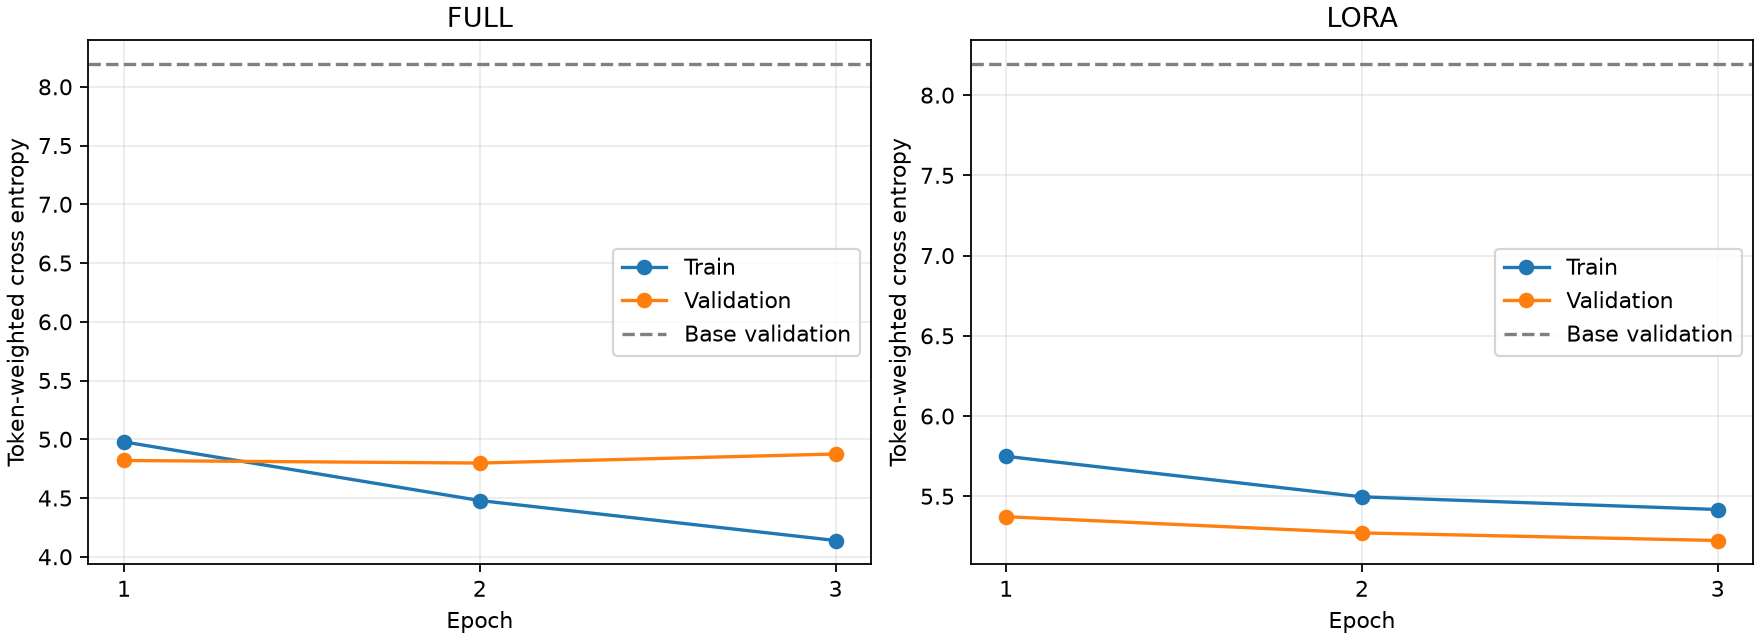

In [5]:
display(Image(filename=str(RUN_DIR / "loss_curves.png")))

## 5. 동일 프롬프트 5개의 생성 결과

평가 전에 정한 문장 앞부분 5개를 사용한다. 세 모델은 동일한 seed, temperature, top_p, top_k, 반복 억제 설정을 적용한다. 아래 continuation은 입력 뒤에 생성된 부분만 표시한다. 출력 길이가 짧은 경우 EOS를 일찍 생성했을 수 있으며, 생성 품질을 단정하지 않고 표현·문맥 연결·반복을 함께 확인한다.

In [6]:
display(pd.DataFrame([report["generation_settings"]]))
for i, prompt in enumerate(report["prompts"]):
    display(Markdown(f"### 프롬프트 {i+1}: {prompt}"))
    for method in ["base", "full", "lora"]:
        generated = report["models"][method]["generations"][i]
        assert generated["prompt"] == prompt
        print(f"[{method}] {generated['continuation'] or '(즉시 종료)'}\n")

,max_new_tokens,do_sample,temperature,top_p,top_k,repetition_penalty,no_repeat_ngram_size
0,40,True,0.8,0.9,50,1.1,3


### 프롬프트 1: 오늘 바당에 가 보니까

[base] 우리 쪽에서는 이쪽에서는 이제 다들 지금 거의 이거 어떻게 할 거냐 이러면서 뭐~ 이러고 있는 그런 상황이죠.
예. 아까 저희가 어제 오후에 봤는데 네

[full] 우리 아방도

[lora] 이제 그걸로 하면은 이제 다 해먹을 수 있는디



### 프롬프트 2: 우리 어멍이 아침에

[base] 일어나면 두 개의 얼굴이 마주친다.
그 얼굴에는 각각 다른 의미를 지닌 한 명의 얼굴이 겹쳐진다.
그 얼굴은 항상 다르다.
또한 다른 얼굴들은 서로 다른 의미를 지닌다.
우리는 각기 다른 표정으로 사물을 바라보는가

[full] 일어나서 저녁이나

[lora] 일어나면 뭔가 



### 프롬프트 3: 친구하고 시장에 가서

[base] 장사하는 게 아니라면 지금부터라도 시장 상황을 정확히 알아야 한다.
또한 내가 시장을 직접 보는 것도 좋다.
그래서 그 시장이 너무 조용하면 안 된다.
시장 분위기가 잘 형성돼 있기 때문에 여러 가지 마케팅

[full] 팔고 싶댄

[lora] 막 겅 했댄



### 프롬프트 4: 어릴 때 우리 동네에서는

[base] 거의 초등학교 3학년 때부터 니까..
"우리 학교 다닐 때는 학교 다닐 때도 니더."
"그럼 우리 집은 왜 이렇게 안 좋아할까?"
나는 가 그런

[full] 막 겅해가지고 겅해신디

[lora] 우리 엄마한테 겅했댄 이름



### 프롬프트 5: 비가 많이 오는 날에는

[base] 빗방울이 떨어지는 곳이 있겠다.
낮 최고기온은 서울 18도, 인천 16도, 수원 17도, 춘천 15도, 강릉 20도, 청주 19도, 대전 19도, 전주 21도, 광주 21도, 대구 21

[full] 아무 때나 겅 하지 않으믄

[lora] 비 내리는 날에도 비가 내리고 비는 내려 불어나면 이



## 6. 결과 분석과 결론

아래 결론은 실제 측정값으로 작성한다. 생성 품질을 PPL만으로 추정하지 않으며, 이 실험의 조건과 한계를 함께 명시한다.

In [7]:
display(Markdown((RUN_DIR / "conclusion.md").read_text(encoding="utf-8")))

# 측정 결과에 근거한 결론

전체 미세조정의 테스트 PPL은 135.043이며 원본 2835.041 대비 95.24% 감소했다. 이 비교는 같은 토크나이저와 토큰화 조건의 도메인 예측 오차를 나타낸다.

LoRA의 테스트 PPL은 190.083이며 원본 2835.041 대비 93.30% 감소했다. 미세조정 방식에 따라 도메인 적응의 정도가 달랐다.

LoRA의 학습 파라미터 수는 전체 미세조정의 0.236%이다. 순수 학습 시간은 Full 299.5초, LoRA 172.3초로 측정되었으며, 파라미터 감소율과 시간 감소율은 동일하지 않다.

동일 프롬프트 5개의 생성 결과를 아래 출력으로 비교한다. PPL만으로 자연스러운 제주어 사용이나 사실 정확성을 판정할 수 없으며, 짧은 응답·반복·문맥 연결은 별도 정성 검토가 필요하다.

대화 파일 간 분리와 완전 동일 문장 제거를 적용했지만, 파일 간 화자 중복이나 유사 문장까지 배제한 것은 아니다. 단일 시드·선택한 표본·학습 설정에서의 결과이며 독립 화자 전체에 대한 성능으로 일반화하지 않는다.


## 재현 방법 및 참고

프로젝트 루트에서 다음 순서로 실행한다.

```bash
bash setup.sh
# prepared/가 없다면 원천 JSON으로 먼저 준비
python prepare_data.py --source "/원천/JSON/폴더" --max-files 300
python experiment.py
```

준비된 prepared/ 폴더를 사용하면 원천 JSON을 GPU Pod에 다시 업로드할 필요가 없다. 실험 결과와 가중치는 outputs/assignment4/에 저장되며, 이 디렉터리의 실행 결과가 포함된 노트북이 제출본이다. 학습이 끝났는데 노트북 생성만 실패하면 `python make_report.py --run-dir outputs/assignment4`로 재생성할 수 있다.

- [AI Hub 한국어 방언 발화(제주도)](https://www.aihub.or.kr/aihubdata/data/view.do?dataSetSn=121)
- [KoGPT2 모델 카드](https://huggingface.co/skt/kogpt2-base-v2)
- [Hugging Face PEFT LoRA](https://huggingface.co/docs/peft/package_reference/lora)
- [Hugging Face Perplexity](https://huggingface.co/docs/transformers/perplexity)

학습된 가중치와 원천 데이터의 배포에는 각각의 이용 조건이 적용된다. 본 실험은 원천 음성 인식 성능을 평가하는 실험이 아니다.